# Antimalarial XGBoost Model — XGB-1 (Avalon + 5 Descriptors)
## Based on: *Kore et al., BMC Chemistry, 2025* — https://doi.org/10.1186/s13065-025-01395-4

**Feature matrix:** Avalon MFP (1024 bits) **concatenated** with 5 physicochemical descriptors:
| # | Descriptor | Source |
|---|-----------|--------|
| 1 | **MW** — Molecular Weight | OpenChemLib |
| 2 | **TPSA** — Topological Polar Surface Area | OpenChemLib |
| 3 | **cLogP** — Calculated partition coefficient | OpenChemLib |
| 4 | **AromaticRings** — Number of aromatic rings | OpenChemLib |
| 5 | **BaN** — Basic Nitrogen count | OpenChemLib (pKa-based port of AtomFunctionAnalyzer) |

**Model:** XGBoost (`xgboost.XGBClassifier`)  
**Input:** Pre-split CSV files (train / validation / test) — no ChEMBL fetch or re-splitting needed.

> **Descriptor backend:** OpenChemLib-JS (via Node.js subprocess). All 5 descriptors are calculated
> using `openchemlib` npm package — no DataWarrior required.

## 0. Install Dependencies

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = '/content/drive/MyDrive/antimalarial_project/'

import os
os.makedirs(PROJECT_DIR, exist_ok=True)

import matplotlib.pyplot as plt

def save_fig(filename, dpi=150):
    path = PROJECT_DIR + filename
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f"Saved to Drive: {path}")

print(f"PROJECT_DIR: {PROJECT_DIR}")
print("Drive mounted and ready.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR: /content/drive/MyDrive/antimalarial_project/
Drive mounted and ready.


In [ ]:
import subprocess, sys

# Core packages
for pkg in ["rdkit", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "tqdm", "xgboost"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

# OpenChemLib-JS via npm
subprocess.run(['npm', 'install', 'openchemlib', '--prefix', '/tmp/ocl'],
               check=True, capture_output=True)
print("All packages installed (including openchemlib-JS and xgboost).")

All packages installed (including openchemlib-JS and xgboost).


## 1. Imports

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import subprocess, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from tqdm.notebook import tqdm
import pickle, os

# RDKit — only for Avalon fingerprints and SMILES validation
from rdkit import Chem, DataStructs

# Avalon
try:
    from rdkit.Avalon import pyAvalonTools
    AVALON_AVAILABLE = True
    print("Avalon fingerprints available")
except ImportError:
    AVALON_AVAILABLE = False
    print("WARNING: Avalon not available. Falling back to RDKit topological FP.")

# XGBoost
import xgboost as xgb
from xgboost import XGBClassifier
print(f"XGBoost version: {xgb.__version__}")

# Scikit-learn
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, matthews_corrcoef,
    cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

print("All imports successful")

Avalon fingerprints available
XGBoost version: 3.2.0
All imports successful


## 2. Configuration

In [ ]:
# ============================================================
#  EDIT THESE to match your files
# ============================================================

TRAIN_CSV  = "train.csv"        # 60% — used for XGB training
VAL_CSV    = "validation.csv"   # 20% — used for hyperparameter optimisation
TEST_CSV   = "test.csv"         # 20% — held-out external test set

SMILES_COL = "Molecule (RDKit Mol) (Canonical)"  # Column with SMILES strings
LABEL_COL  = "Category"                           # Activity: Active / Inactive

AVALON_NBITS = 1024   # Paper used 1024
DESC_NAMES   = ['MW', 'TPSA', 'cLogP', 'AromaticRings', 'BaN']

# Label mapping (string → int)
LABEL_MAP = {'Active': 1, 'Inactive': 0}

print(f"Train CSV  : {TRAIN_CSV}")
print(f"Val CSV    : {VAL_CSV}")
print(f"Test CSV   : {TEST_CSV}")
print(f"SMILES col : {SMILES_COL}")
print(f"Label col  : {LABEL_COL}")
print(f"Avalon bits: {AVALON_NBITS}")
print(f"Descriptor backend: OpenChemLib-JS (Node.js)")

Train CSV  : train.csv
Val CSV    : validation.csv
Test CSV   : test.csv
SMILES col : Molecule (RDKit Mol) (Canonical)
Label col  : Category
Avalon bits: 1024
Descriptor backend: OpenChemLib-JS (Node.js)


## 3. Load Pre-Split CSV Files

In [ ]:
def load_csv(path, label):
    df = pd.read_csv(path)
    print(f"{label:20s}: {len(df):,} rows  |  columns: {list(df.columns)}")
    return df

train_df = load_csv(TRAIN_CSV, "Training set")
val_df   = load_csv(VAL_CSV,   "Validation set")
test_df  = load_csv(TEST_CSV,  "External test set")

# Validate required columns
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    for col in [SMILES_COL, LABEL_COL]:
        assert col in df.columns, f"Column '{col}' not found in {name} CSV!"

# Class distribution
print("\nClass distribution:")
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    vc = df[LABEL_COL].value_counts()
    print(f"  {name:8s}: Active={vc.get('Active', 0):,}  Inactive={vc.get('Inactive', 0):,}  Total={len(df):,}")

Training set        : 9,070 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']
Validation set      : 3,024 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']
External test set   : 3,024 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']

Class distribution:
  Train   : Active=4,223  Inactive=4,847  Total=9,070
  Val     : Active=1,408  Inactive=1,616  Total=3,024
  Test    : Active=1,408  Inactive=1,616  Total=3,024


## 4. Descriptor Calculation

### Feature Vector = Avalon FP (1024 bits) + 5 Descriptors = 1029 features

Same descriptor pipeline as the RF notebook — descriptors computed via **OpenChemLib-JS**,
z-score standardised using a scaler fitted on training set only.

In [ ]:
import subprocess, json
import numpy as np

_OCL_LIB = '/tmp/ocl/node_modules/openchemlib/dist/openchemlib.js'

_OCL_JS_SCRIPT = r"""
const OCL = require('""" + _OCL_LIB + r"""');
const { Molecule, MoleculeProperties } = OCL;

function getFakeOxoCount(mol, atom) {
  let n = 0;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    const no = mol.getAtomicNo(mol.getConnAtom(atom, i));
    if (mol.getConnBondOrder(atom, i) === 2 && (no===7||no===8||no===16)) n++;
  }
  return n;
}

function isStabilized(mol, atom, twice) {
  let found = false;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    const bond = mol.getConnBond(atom, i);
    if (!mol.isAromaticBond(bond) && mol.getConnBondOrder(atom, i) === 1) {
      const conn = mol.getConnAtom(atom, i);
      if (!mol.isAromaticAtom(conn) &&
          ((mol.getAtomicNo(conn)===6 && getFakeOxoCount(mol,conn)===1) ||
           (mol.getAtomicNo(conn)===16 && getFakeOxoCount(mol,conn)===2))) {
        if (found || !twice) return true;
        found = true;
      }
    }
  }
  return false;
}

function isVinylogFakeOxo(mol, atom) {
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    if (mol.getConnBondOrder(atom, i) !== 1) {
      const conn = mol.getConnAtom(atom, i);
      for (let j = 0; j < mol.getConnAtoms(conn); j++)
        if (mol.getConnBondOrder(conn,j)===1 && getFakeOxoCount(mol,mol.getConnAtom(conn,j))!==0)
          return true;
    }
  }
  return false;
}

function isBasicNitrogen(mol, atom) {
  if (mol.getAtomicNo(atom) !== 7) return false;
  if (mol.getAtomCharge(atom) !== 0) return false;
  if (mol.getConnAtoms(atom) + mol.getAtomPi(atom) > 3) return false;
  if (mol.isAromaticAtom(atom)) {
    if (mol.getAtomPi(atom) !== 1) return false;
    let donorCount = 0;
    for (let i = 0; i < mol.getConnAtoms(atom); i++) {
      const conn = mol.getConnAtom(atom, i);
      if (!mol.isAromaticAtom(conn)) continue;
      for (let j = 0; j < mol.getConnAtoms(conn); j++) {
        const c2 = mol.getConnAtom(conn, j);
        if (c2 === atom) continue;
        const no = mol.getAtomicNo(c2);
        if ((no===7||no===8) && mol.getConnAtoms(c2)<3) donorCount++;
      }
    }
    return donorCount >= 1;
  } else {
    if (mol.getAtomPi(atom) !== 0) return false;
    if (getFakeOxoCount(mol, atom) !== 0) return false;
    if (isStabilized(mol, atom, false)) return false;
    if (isVinylogFakeOxo(mol, atom)) return false;
    return true;
  }
}

function basicNitrogenCount(mol) {
  let count = 0;
  for (let i = 0; i < mol.getAllAtoms(); i++) {
    if (isBasicNitrogen(mol, i)) count++;
  }
  return count;
}

const smilesList = JSON.parse(process.argv[2]);
const results = {};

for (const smi of smilesList) {
  try {
    const mol = OCL.Molecule.fromSmiles(smi);
    mol.ensureHelperArrays(OCL.Molecule.cHelperRings | OCL.Molecule.cHelperAromaticity | OCL.Molecule.cHelperParities);
    const props = new MoleculeProperties(mol);
    const formula = mol.getMolecularFormula();
    results[smi] = [
      formula.relativeWeight,
      props.polarSurfaceArea,
      props.logP,
      mol.getAromaticRingCount(),
      basicNitrogenCount(mol)
    ];
  } catch(e) {
    results[smi] = null;
  }
}

process.stdout.write(JSON.stringify(results));
"""

def run_ocl_descriptors(smiles_list):
    """Run OpenChemLib-JS descriptor calculation via Node.js subprocess."""
    script_path = '/tmp/ocl_desc.js' # Changed from .mjs to .js
    with open(script_path, 'w') as f:
        f.write(_OCL_JS_SCRIPT)

    BATCH_SIZE = 500
    all_results = {}
    for i in range(0, len(smiles_list), BATCH_SIZE):
        batch = smiles_list[i:i+BATCH_SIZE]
        result = subprocess.run(
            ['node', script_path, json.dumps(batch)],
            capture_output=True, text=True, timeout=120
        )
        if result.returncode != 0:
            print(f"OCL error batch {i}: {result.stderr[:200]}")
            continue
        batch_res = json.loads(result.stdout)
        for smi, vals in batch_res.items():
            if vals is not None:
                all_results[smi] = np.array(vals, dtype=np.float32)
    return all_results


def calc_avalon_fp(mol, n_bits=1024):
    if AVALON_AVAILABLE:
        bv = pyAvalonTools.GetAvalonFP(mol, nBits=n_bits)
    else:
        from rdkit.Chem import RDKFingerprint
        bv = RDKFingerprint(mol, fpSize=n_bits)
    arr = np.zeros(n_bits, dtype=np.float32)
    DataStructs.ConvertToNumpyArray(bv, arr)
    return arr


print("OCL descriptor functions defined.")

OCL descriptor functions defined.


In [ ]:
def build_feature_matrix(df, smiles_col, label_col,
                          n_bits=1024, scaler=None, fit_scaler=False, set_name="Set"):
    """
    Build X = [Avalon FP | standardised 5 descriptors], y = labels.
    Returns: X, y, valid_df, fp_matrix, [scaler if fit_scaler else None]
    """
    print(f"\nBuilding features for {set_name} ({len(df):,} molecules)...")

    # Step 1: validate SMILES
    valid_idx, valid_smiles = [], []
    for original_idx, row in df.iterrows():
        mol = Chem.MolFromSmiles(str(row[smiles_col]))
        if mol is not None:
            valid_idx.append(original_idx)
            valid_smiles.append(str(row[smiles_col]))

    valid_df = df.loc[valid_idx].reset_index(drop=True)
    print(f"  Dropped: {len(df) - len(valid_idx)} invalid SMILES")

    # Step 2: batch descriptor calculation
    print(f"  [OCL] Calculating descriptors for {len(valid_smiles)} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles)

    # Step 3: build matrices
    fp_list, desc_list, keep_idx = [], [], []
    for i, (smi, orig_idx) in enumerate(zip(valid_smiles, valid_idx)):
        if smi not in desc_map:
            continue
        mol = Chem.MolFromSmiles(smi)
        try:
            fp = calc_avalon_fp(mol, n_bits=n_bits)
        except Exception as e:
            print(f"  FP error for {smi}: {e}")
            continue
        fp_list.append(fp)
        desc_list.append(desc_map[smi])
        keep_idx.append(i)

    valid_df = valid_df.iloc[keep_idx].reset_index(drop=True)
    fp_mat   = np.array(fp_list, dtype=np.float32)
    desc_mat = np.array(desc_list, dtype=np.float32)

    # Step 4: standardise descriptors
    if fit_scaler:
        scaler = StandardScaler()
        desc_scaled = scaler.fit_transform(desc_mat)
        print(f"  Scaler fitted on {set_name}")
    else:
        desc_scaled = scaler.transform(desc_mat)

    X = np.hstack([fp_mat, desc_scaled]).astype(np.float32)
    y = valid_df[label_col].map(LABEL_MAP).values.astype(np.int32)

    print(f"  Final shape: X={X.shape}, y={y.shape}")
    print(f"  Class balance: Active={y.sum()}, Inactive={(y==0).sum()}")

    if fit_scaler:
        return X, y, valid_df, fp_mat, scaler
    return X, y, valid_df, fp_mat, None


# Build train features and fit scaler
X_train, y_train, train_valid_df, X_train_fp, scaler = build_feature_matrix(
    train_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, fit_scaler=True, set_name="Training"
)

# Build val features
X_val, y_val, val_valid_df, X_val_fp, _ = build_feature_matrix(
    val_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, scaler=scaler, fit_scaler=False, set_name="Validation"
)

# Build test features
X_test, y_test, test_valid_df, X_test_fp, _ = build_feature_matrix(
    test_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, scaler=scaler, fit_scaler=False, set_name="Test"
)

# Dev set = train + val (used for final model and CV)
X_dev = np.vstack([X_train, X_val])
y_dev = np.concatenate([y_train, y_val])
X_dev_fp = np.vstack([X_train_fp, X_val_fp])
print(f"\nDev set: {X_dev.shape[0]:,} samples (train + val)")


Building features for Training (9,070 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 9070 molecules...
  Scaler fitted on Training
  Final shape: X=(9070, 1029), y=(9070,)
  Class balance: Active=4223, Inactive=4847

Building features for Validation (3,024 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 3024 molecules...
  Final shape: X=(3024, 1029), y=(3024,)
  Class balance: Active=1408, Inactive=1616

Building features for Test (3,024 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 3024 molecules...
  Final shape: X=(3024, 1029), y=(3024,)
  Class balance: Active=1408, Inactive=1616

Dev set: 12,094 samples (train + val)


## 5. Evaluation Metrics

In [ ]:
def compute_metrics(y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    m = {
        'Accuracy':    accuracy_score(y_true, y_pred),
        'Precision':   precision_score(y_true, y_pred, zero_division=0),
        'Sensitivity': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'F1':          f1_score(y_true, y_pred, zero_division=0),
        'Kappa':       cohen_kappa_score(y_true, y_pred),
        'MCC':         matthews_corrcoef(y_true, y_pred),
    }
    if y_prob is not None:
        m['AUROC'] = roc_auc_score(y_true, y_prob)
    m.update({'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn)})
    return m


def print_metrics(m, title="Metrics"):
    print(f"\n{'='*52}\n  {title}\n{'='*52}")
    for k, v in m.items():
        print(f"  {k:15s}: {v:.4f}" if isinstance(v, float) else f"  {k:15s}: {v}")

print("Metrics functions ready")

Metrics functions ready


## 6. Hyperparameter Optimisation

Grid search over key XGBoost parameters evaluated on the internal validation set.

| Parameter | Description | Grid |
|-----------|-------------|------|
| `n_estimators` | Number of boosting rounds | [100, 200, 300] |
| `max_depth` | Max tree depth | [4, 6, 8] |
| `learning_rate` | Step size shrinkage | [0.05, 0.1, 0.2] |
| `subsample` | Row subsampling ratio | [0.8, 1.0] |
| `colsample_bytree` | Feature subsampling ratio | [0.8, 1.0] |

In [ ]:
QUICK_RUN = True   # Set False for full grid search

# Compute class imbalance weight for scale_pos_weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
SCALE_POS_WEIGHT = neg_count / pos_count
print(f"Class ratio (neg/pos): {SCALE_POS_WEIGHT:.2f} — using as scale_pos_weight")

if QUICK_RUN:
    param_grid = {
        'n_estimators':     [100, 200, 300],
        'max_depth':        [4, 6, 8],
        'learning_rate':    [0.05, 0.1, 0.2],
        'subsample':        [0.8, 1.0],
        'colsample_bytree': [0.8, 1.0],
    }
else:
    param_grid = {
        'n_estimators':     [100, 200, 300, 400, 500],
        'max_depth':        [3, 4, 6, 8, 10],
        'learning_rate':    [0.01, 0.05, 0.1, 0.2, 0.3],
        'subsample':        [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    }

# Build all combinations
from itertools import product as iterproduct
all_combos = list(iterproduct(
    param_grid['n_estimators'],
    param_grid['max_depth'],
    param_grid['learning_rate'],
    param_grid['subsample'],
    param_grid['colsample_bytree'],
))
print(f"Total combinations: {len(all_combos)}")

hp_rows = []
best_auroc = -1

with tqdm(total=len(all_combos), desc="Grid search") as pbar:
    for (nE, mD, lr, ss, cbt) in all_combos:
        model = XGBClassifier(
            n_estimators=nE,
            max_depth=mD,
            learning_rate=lr,
            subsample=ss,
            colsample_bytree=cbt,
            scale_pos_weight=SCALE_POS_WEIGHT,
            use_label_encoder=False,
            eval_metric='logloss',
            n_jobs=-1,
            random_state=42,
            verbosity=0,
        )
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
        yp   = model.predict(X_val)
        ypr  = model.predict_proba(X_val)[:, 1]
        acc  = accuracy_score(y_val, yp)
        auroc = roc_auc_score(y_val, ypr)
        hp_rows.append({
            'n_estimators': nE, 'max_depth': mD,
            'learning_rate': lr, 'subsample': ss,
            'colsample_bytree': cbt,
            'val_accuracy': acc,
            'val_auroc': auroc,
        })
        pbar.update(1)

hp_results = pd.DataFrame(hp_rows)
# Best by AUROC (more robust than accuracy for imbalanced data)
best_row = hp_results.loc[hp_results['val_auroc'].idxmax()]

best_nE  = int(best_row.n_estimators)
best_mD  = int(best_row.max_depth)
best_lr  = float(best_row.learning_rate)
best_ss  = float(best_row.subsample)
best_cbt = float(best_row.colsample_bytree)

print(f"\nBest hyperparameters (by val AUROC):")
print(f"  n_estimators     : {best_nE}")
print(f"  max_depth        : {best_mD}")
print(f"  learning_rate    : {best_lr}")
print(f"  subsample        : {best_ss}")
print(f"  colsample_bytree : {best_cbt}")
print(f"  Val Accuracy     : {best_row.val_accuracy:.4f}")
print(f"  Val AUROC        : {best_row.val_auroc:.4f}")

Class ratio (neg/pos): 1.15 — using as scale_pos_weight
Total combinations: 108


Grid search:   0%|          | 0/108 [00:00<?, ?it/s]


Best hyperparameters (by val AUROC):
  n_estimators     : 200
  max_depth        : 8
  learning_rate    : 0.2
  subsample        : 1.0
  colsample_bytree : 0.8
  Val Accuracy     : 0.9170
  Val AUROC        : 0.9700


### 6.1 Hyperparameter Heatmap (n_estimators × max_depth)

Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_hp_heatmap.png


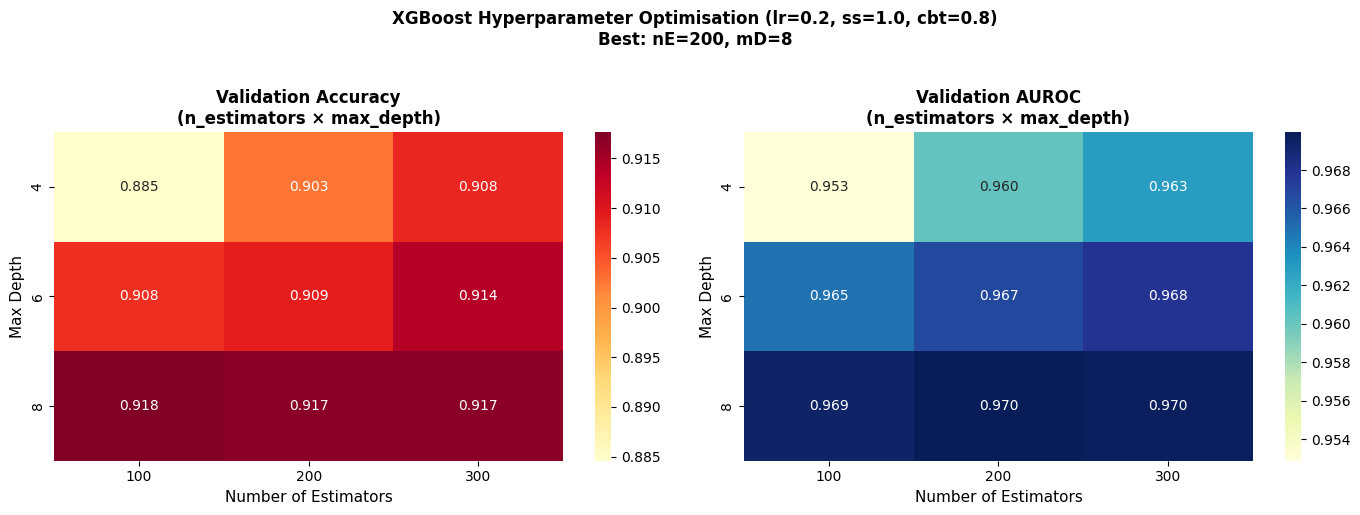

In [ ]:
# Fix best lr/ss/cbt, pivot over nE × mD
subset = hp_results[
    (hp_results['learning_rate'] == best_lr) &
    (hp_results['subsample'] == best_ss) &
    (hp_results['colsample_bytree'] == best_cbt)
]

pivot_acc   = subset.pivot(index='max_depth', columns='n_estimators', values='val_accuracy')
pivot_auroc = subset.pivot(index='max_depth', columns='n_estimators', values='val_auroc')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, piv, title, cmap in zip(axes,
                                  [pivot_acc, pivot_auroc],
                                  ['Validation Accuracy', 'Validation AUROC'],
                                  ['YlOrRd', 'YlGnBu']):
    sns.heatmap(piv, annot=True, fmt='.3f', cmap=cmap, ax=ax)
    ax.set_title(f'{title}\n(n_estimators × max_depth)', fontweight='bold', fontsize=12)
    ax.set_xlabel('Number of Estimators', fontsize=11)
    ax.set_ylabel('Max Depth', fontsize=11)

plt.suptitle(
    f'XGBoost Hyperparameter Optimisation (lr={best_lr}, ss={best_ss}, cbt={best_cbt})\n'
    f'Best: nE={best_nE}, mD={best_mD}',
    fontsize=12, fontweight='bold', y=1.02
)
plt.tight_layout()
save_fig('xgb_hp_heatmap.png')
plt.show()

## 7. Train Final XGBoost Model & Evaluate on External Test Set

In [ ]:
print(f"Training final XGBoost model on dev set ({len(y_dev):,} samples)...")
print(f"  n_estimators={best_nE}, max_depth={best_mD}, lr={best_lr}, "
      f"subsample={best_ss}, colsample_bytree={best_cbt}")

xgb_model = XGBClassifier(
    n_estimators=best_nE,
    max_depth=best_mD,
    learning_rate=best_lr,
    subsample=best_ss,
    colsample_bytree=best_cbt,
    scale_pos_weight=SCALE_POS_WEIGHT,
    use_label_encoder=False,
    eval_metric='logloss',
    n_jobs=-1,
    random_state=42,
    verbosity=0,
)
xgb_model.fit(X_dev, y_dev, eval_set=[(X_test, y_test)], verbose=False)

y_pred_test = xgb_model.predict(X_test)
y_prob_test = xgb_model.predict_proba(X_test)[:, 1]
test_metrics = compute_metrics(y_test, y_pred_test, y_prob_test)

print_metrics(test_metrics,
    "External Test Set — XGB-1 (Avalon 1024 + MW + TPSA + cLogP + AromaticRings + BaN)")
print("\nRF-1 reference (paper target): Acc=0.917 | Prec=0.935 | Sens=0.884 | AUROC=0.973")

Training final XGBoost model on dev set (12,094 samples)...
  n_estimators=200, max_depth=8, lr=0.2, subsample=1.0, colsample_bytree=0.8

  External Test Set — XGB-1 (Avalon 1024 + MW + TPSA + cLogP + AromaticRings + BaN)
  Accuracy       : 0.9322
  Precision      : 0.9368
  Sensitivity    : 0.9162
  Specificity    : 0.9462
  F1             : 0.9264
  Kappa          : 0.8636
  MCC            : 0.8638
  AUROC          : 0.9770
  TP             : 1290
  TN             : 1529
  FP             : 87
  FN             : 118

RF-1 reference (paper target): Acc=0.917 | Prec=0.935 | Sens=0.884 | AUROC=0.973


### 7.1 ROC Curve

Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_roc_curve.png


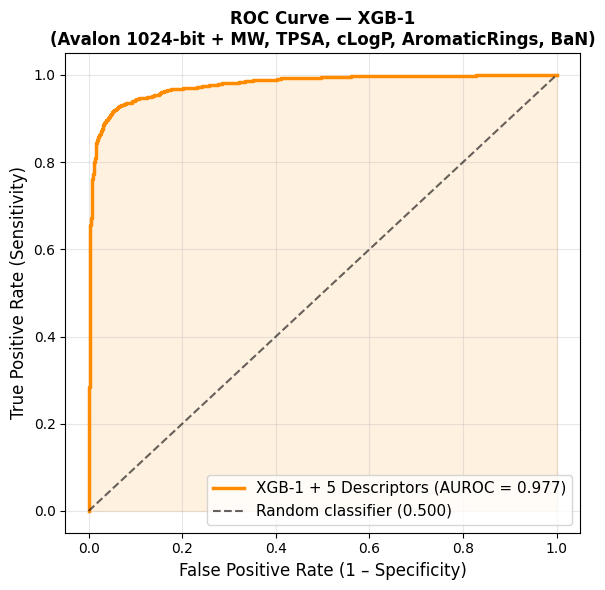

In [ ]:
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
auroc = test_metrics['AUROC']

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2.5,
        label=f'XGB-1 + 5 Descriptors (AUROC = {auroc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6, label='Random classifier (0.500)')
ax.fill_between(fpr, tpr, alpha=0.12, color='darkorange')
ax.set_xlabel('False Positive Rate (1 – Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title('ROC Curve — XGB-1\n(Avalon 1024-bit + MW, TPSA, cLogP, AromaticRings, BaN)',
             fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('xgb_roc_curve.png')
plt.show()

### 7.2 Confusion Matrix

Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_confusion_matrix.png


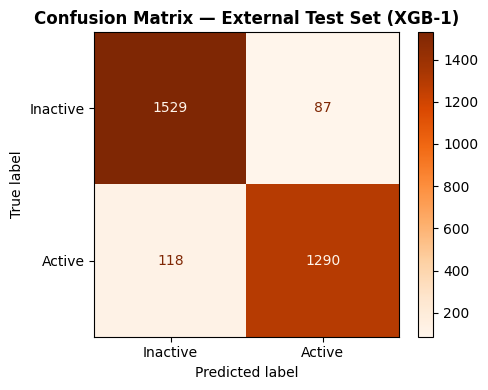

In [ ]:
cm = confusion_matrix(y_test, y_pred_test)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Inactive', 'Active']).plot(
    ax=ax, colorbar=True, cmap='Oranges')
ax.set_title('Confusion Matrix — External Test Set (XGB-1)', fontweight='bold')
plt.tight_layout()
save_fig('xgb_confusion_matrix.png')
plt.show()

## 8. Model Validation

### 8.1 Learning Curve — Validation Loss vs Boosting Rounds

Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_learning_curve.png


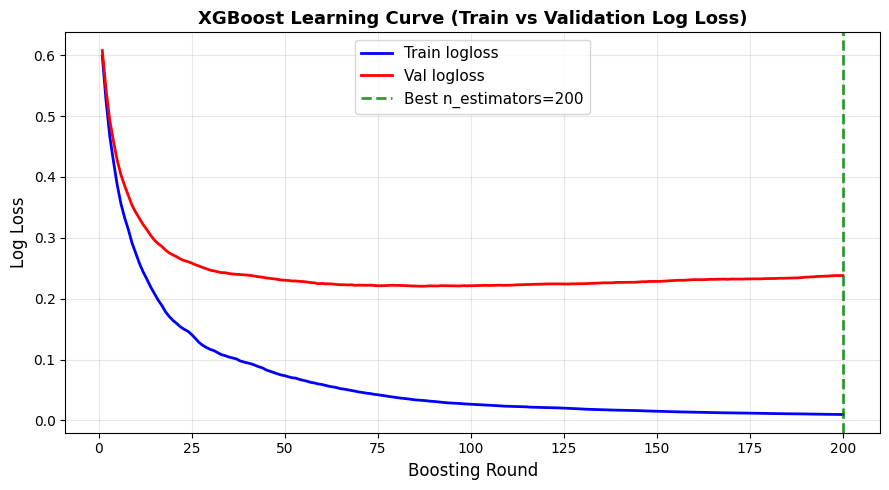

In [ ]:
# Re-train with eval history on val set for the learning curve
xgb_lc = XGBClassifier(
    n_estimators=best_nE,
    max_depth=best_mD,
    learning_rate=best_lr,
    subsample=best_ss,
    colsample_bytree=best_cbt,
    scale_pos_weight=SCALE_POS_WEIGHT,
    use_label_encoder=False,
    eval_metric='logloss',
    n_jobs=-1,
    random_state=42,
    verbosity=0,
)
xgb_lc.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

evals = xgb_lc.evals_result()
train_loss = evals['validation_0']['logloss']
val_loss   = evals['validation_1']['logloss']
rounds     = range(1, len(train_loss) + 1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(rounds, train_loss, 'b-', lw=2, label='Train logloss')
ax.plot(rounds, val_loss,   'r-', lw=2, label='Val logloss')
ax.axvline(best_nE, color='green', ls='--', lw=2, alpha=0.8,
           label=f'Best n_estimators={best_nE}')
ax.set_xlabel('Boosting Round', fontsize=12)
ax.set_ylabel('Log Loss', fontsize=12)
ax.set_title('XGBoost Learning Curve (Train vs Validation Log Loss)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('xgb_learning_curve.png')
plt.show()

### 8.2 10-fold CV × 10 Repeats

In [ ]:
cv_records = []
key_metrics = ['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']

print("Running 10-fold CV x 10 repeats...")
for repeat in tqdm(range(10), desc="CV repeats"):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=repeat)
    fold_m = []
    for tr_idx, v_idx in skf.split(X_dev, y_dev):
        xgb_cv = XGBClassifier(
            n_estimators=best_nE,
            max_depth=best_mD,
            learning_rate=best_lr,
            subsample=best_ss,
            colsample_bytree=best_cbt,
            scale_pos_weight=SCALE_POS_WEIGHT,
            use_label_encoder=False,
            eval_metric='logloss',
            n_jobs=-1,
            random_state=42,
            verbosity=0,
        )
        xgb_cv.fit(X_dev[tr_idx], y_dev[tr_idx])
        m = compute_metrics(
            y_dev[v_idx],
            xgb_cv.predict(X_dev[v_idx]),
            xgb_cv.predict_proba(X_dev[v_idx])[:, 1]
        )
        fold_m.append(m)
    avg = {k: np.mean([fm[k] for fm in fold_m]) for k in key_metrics}
    avg['repeat'] = repeat + 1
    cv_records.append(avg)

cv_df      = pd.DataFrame(cv_records)
cv_summary = cv_df[key_metrics].agg(['mean','std'])
print("\n10-fold CV Results:")
print(cv_summary.round(4).to_string())

Running 10-fold CV x 10 repeats...


CV repeats:   0%|          | 0/10 [00:00<?, ?it/s]


10-fold CV Results:
      Accuracy  Precision  Sensitivity  Specificity      F1   Kappa     MCC   AUROC
mean    0.9205     0.9263       0.9011       0.9374  0.9135  0.8400  0.8404  0.9710
std     0.0010     0.0017       0.0017       0.0016  0.0011  0.0021  0.0021  0.0005


### 8.3 Y-Scrambling Validation

Y-scrambling:   0%|          | 0/100 [00:00<?, ?it/s]


Y-Scrambling Validation:
  Real model accuracy   : 0.9322
  Scrambled mean ± std  : 0.5036 ± 0.0080
  Expected (random)     : ~0.500
Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_y_scrambling.png


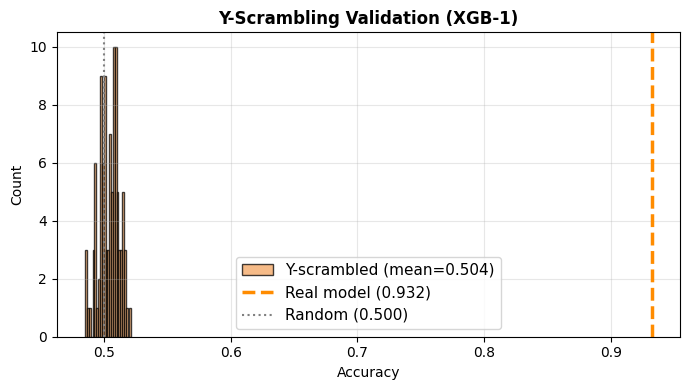

In [ ]:
rng = np.random.RandomState(42)
scrambled_accs = [accuracy_score(rng.permutation(y_test), y_pred_test)
                  for _ in tqdm(range(100), desc="Y-scrambling")]

print(f"\nY-Scrambling Validation:")
print(f"  Real model accuracy   : {test_metrics['Accuracy']:.4f}")
print(f"  Scrambled mean ± std  : {np.mean(scrambled_accs):.4f} ± {np.std(scrambled_accs):.4f}")
print(f"  Expected (random)     : ~0.500")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scrambled_accs, bins=25, color='sandybrown', alpha=0.75, edgecolor='k',
        label=f'Y-scrambled (mean={np.mean(scrambled_accs):.3f})')
ax.axvline(test_metrics['Accuracy'], color='darkorange', lw=2.5, ls='--',
           label=f"Real model ({test_metrics['Accuracy']:.3f})")
ax.axvline(0.5, color='gray', lw=1.5, ls=':', label='Random (0.500)')
ax.set_xlabel('Accuracy'); ax.set_ylabel('Count')
ax.set_title('Y-Scrambling Validation (XGB-1)', fontweight='bold')
ax.legend(fontsize=11); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('xgb_y_scrambling.png')
plt.show()

## 9. Applicability Domain (APD)

Computing APD (Euclidean NN distances in Avalon space)...
  APD threshold (P99): 14.968
  Outside APD: 7/3024 (0.2%)
Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_applicability_domain.png


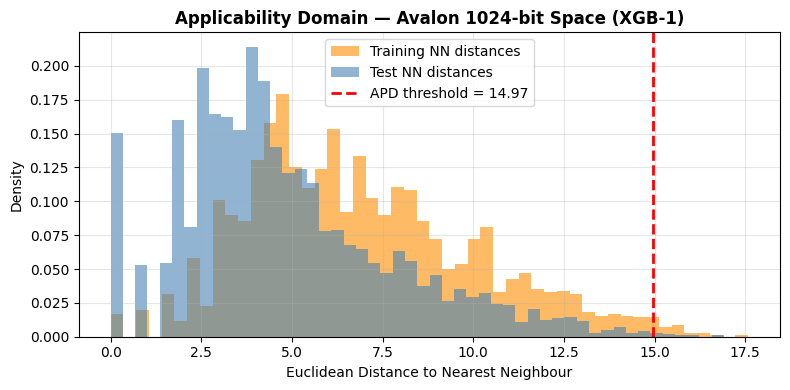

In [ ]:
n_samp = min(2000, len(X_train_fp))
samp_idx = np.random.choice(len(X_train_fp), n_samp, replace=False)
X_samp = X_train_fp[samp_idx]

print("Computing APD (Euclidean NN distances in Avalon space)...")
tr_d = cdist(X_samp, X_samp, metric='euclidean')
np.fill_diagonal(tr_d, np.inf)
train_nn_d = tr_d.min(axis=1)

APD_PERCENTILE = 99
apd_threshold  = np.percentile(train_nn_d, APD_PERCENTILE)

test_nn_d   = cdist(X_test_fp, X_train_fp, metric='euclidean').min(axis=1)
outside_apd = test_nn_d > apd_threshold

print(f"  APD threshold (P{APD_PERCENTILE}): {apd_threshold:.3f}")
print(f"  Outside APD: {outside_apd.sum()}/{len(X_test)} ({100*outside_apd.mean():.1f}%)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_nn_d, bins=50, alpha=0.6, color='darkorange', density=True, label='Training NN distances')
ax.hist(test_nn_d,  bins=50, alpha=0.6, color='steelblue',  density=True, label='Test NN distances')
ax.axvline(apd_threshold, color='red', lw=2, ls='--',
           label=f'APD threshold = {apd_threshold:.2f}')
ax.set_xlabel('Euclidean Distance to Nearest Neighbour')
ax.set_ylabel('Density')
ax.set_title('Applicability Domain — Avalon 1024-bit Space (XGB-1)', fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('xgb_applicability_domain.png')
plt.show()

## 10. Feature Importance

Feature importance — 5 descriptors:
  MW             : 0.001253  ||||||
  TPSA           : 0.000559  ||
  cLogP          : 0.000587  ||
  AromaticRings  : 0.001834  |||||||||
  BaN            : 0.001747  ||||||||

  Avalon bits (sum)  : 0.994020
  Descriptors (sum)  : 0.005980
Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_feature_importance.png


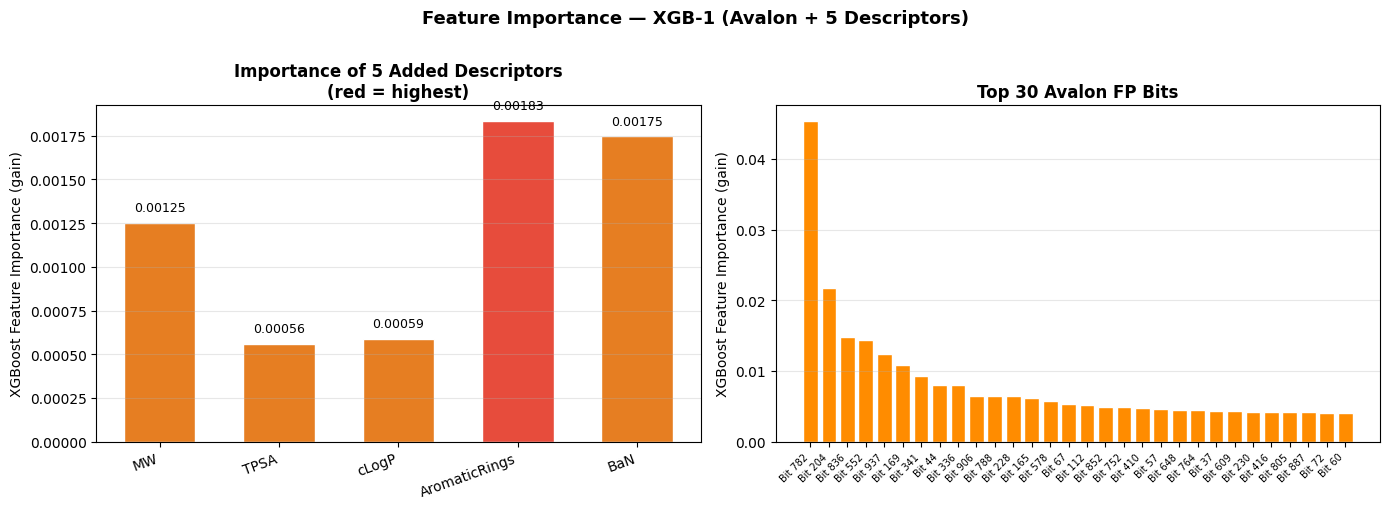

In [ ]:
importances = xgb_model.feature_importances_
avalon_imp  = importances[:AVALON_NBITS]
desc_imp    = importances[AVALON_NBITS:]

print("Feature importance — 5 descriptors:")
for name, val in zip(DESC_NAMES, desc_imp):
    print(f"  {name:15s}: {val:.6f}  {'|' * int(val*5000)}")
print(f"\n  Avalon bits (sum)  : {avalon_imp.sum():.6f}")
print(f"  Descriptors (sum)  : {desc_imp.sum():.6f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: 5 descriptor importances
ax = axes[0]
bar_colors = ['#e74c3c' if v == desc_imp.max() else '#e67e22' for v in desc_imp]
bars = ax.bar(DESC_NAMES, desc_imp, color=bar_colors, edgecolor='white', width=0.6)
for b, v in zip(bars, desc_imp):
    ax.text(b.get_x() + b.get_width()/2, v + 0.00005,
            f'{v:.5f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('XGBoost Feature Importance (gain)')
ax.set_title('Importance of 5 Added Descriptors\n(red = highest)', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

# Right: top 30 Avalon bits
ax2 = axes[1]
top30 = np.argsort(avalon_imp)[::-1][:30]
ax2.bar(range(30), avalon_imp[top30], color='darkorange', edgecolor='white')
ax2.set_xticks(range(30))
ax2.set_xticklabels([f'Bit {top30[i]}' for i in range(30)],
                    rotation=45, ha='right', fontsize=7)
ax2.set_ylabel('XGBoost Feature Importance (gain)')
ax2.set_title('Top 30 Avalon FP Bits', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Feature Importance — XGB-1 (Avalon + 5 Descriptors)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
save_fig('xgb_feature_importance.png')
plt.show()

## 11. Virtual Screening — Predict New Compounds

In [ ]:
def screen_compounds(smiles_list, names=None):
    """
    Screen new SMILES strings using the trained XGB-1 model.
    Descriptors are calculated via OpenChemLib-JS.

    Parameters
    ----------
    smiles_list : list of SMILES
    names       : list of compound names (optional)
    """
    valid_entries, results = [], []
    for i, smi in enumerate(smiles_list):
        name = names[i] if names else f"Cpd_{i+1}"
        mol  = Chem.MolFromSmiles(str(smi))
        if mol is None:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': 'Invalid SMILES', 'P(Active)': None,
                            'Within_APD': None, **{d: None for d in DESC_NAMES}})
        else:
            valid_entries.append((i, name, smi))

    if not valid_entries:
        return pd.DataFrame(results)

    valid_smiles = [e[2] for e in valid_entries]
    print(f"[OCL] Calculating descriptors for {len(valid_smiles)} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles)

    for (i, name, smi) in valid_entries:
        if smi not in desc_map:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': 'OCL error', 'P(Active)': None,
                            'Within_APD': None, **{d: None for d in DESC_NAMES}})
            continue
        try:
            mol      = Chem.MolFromSmiles(smi)
            desc     = desc_map[smi]
            fp       = calc_avalon_fp(mol, n_bits=AVALON_NBITS)
            desc_sc  = scaler.transform(desc.reshape(1, -1))[0]
            feat     = np.hstack([fp, desc_sc]).reshape(1, -1).astype(np.float32)

            pred     = xgb_model.predict(feat)[0]
            prob     = float(xgb_model.predict_proba(feat)[0][1])
            nn_dist  = cdist(fp.reshape(1, -1), X_train_fp, metric='euclidean').min()
            in_apd   = bool(nn_dist <= apd_threshold)

            results.append({
                'Name':        name,
                'SMILES':      smi,
                'Prediction':  'Active' if pred == 1 else 'Inactive',
                'P(Active)':   round(prob, 4),
                'Within_APD':  in_apd,
                'NN_Distance': round(float(nn_dist), 3),
                **{d: round(float(desc[j]), 3) for j, d in enumerate(DESC_NAMES)}
            })
        except Exception as e:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': f'Error: {e}', 'P(Active)': None,
                            'Within_APD': None, **{d: None for d in DESC_NAMES}})

    return pd.DataFrame(results)


# --- Example: screen known antimalarials ---
example_smiles = [
    "CCc1cc2nc3cc(OC)ccc3c(=O)c2cc1OC",             # Quinine
    "ClC1=CC=C(C=C1)C(O)CN2CCN(CC2)C3=NC4=CC=CC=C4N3",  # Clotrimazole (not antimalarial)
    "OC(=O)c1cc(=O)c2cc(OC(=O)C)ccc2o1",             # Aspirin-like (inactive)
]
example_names = ["Quinine", "Clotrimazole", "Aspirin-like"]

screen_df = screen_compounds(example_smiles, names=example_names)
print("\nVirtual Screening Results:")
print(screen_df[['Name', 'Prediction', 'P(Active)', 'Within_APD', 'NN_Distance'] + DESC_NAMES].to_string(index=False))

[19:06:50] Can't kekulize mol.  Unkekulized atoms: 2 3 4 5 6 7 8 11 12 13 16 17 18


[OCL] Calculating descriptors for 2 molecules...

Virtual Screening Results:
        Name     Prediction  P(Active) Within_APD  NN_Distance      MW  TPSA  cLogP  AromaticRings  BaN
     Quinine Invalid SMILES        NaN       None          NaN     NaN   NaN    NaN            NaN  NaN
Clotrimazole         Active     0.7197       True        8.485 356.856 55.39  2.791            3.0  3.0
Aspirin-like       Inactive     0.0013       True        8.062 248.190 89.90  0.789            1.0  0.0


## 12. Summary Dashboard

Saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb_summary_dashboard.png


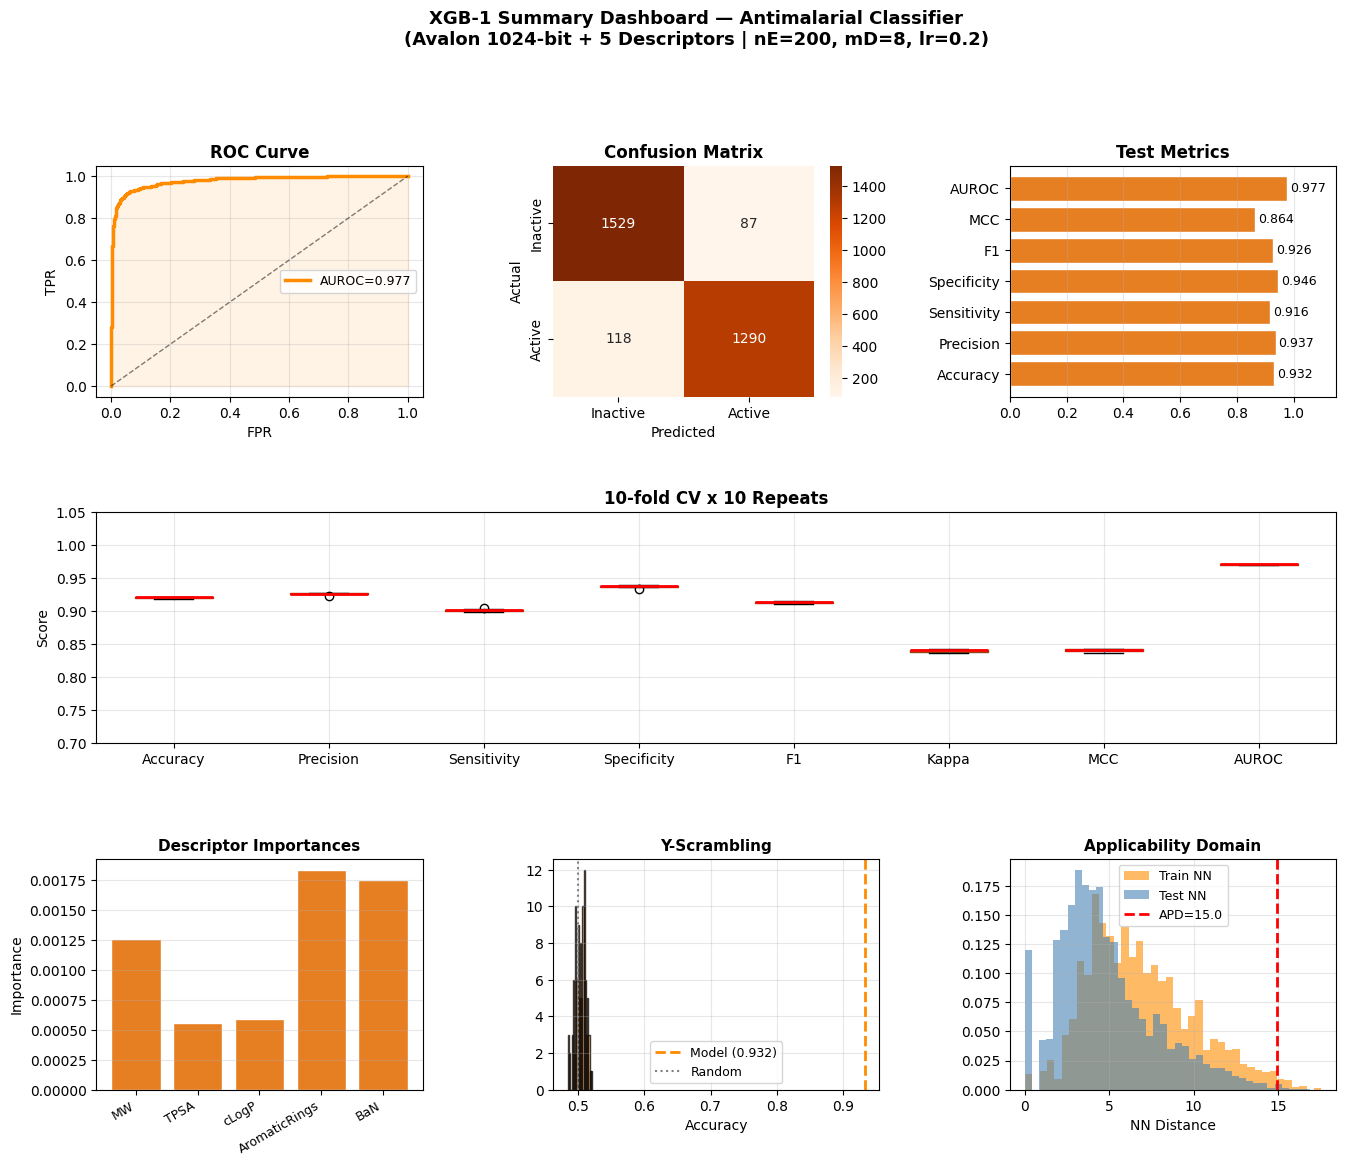

In [ ]:
fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.4)

# ROC
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(fpr, tpr, 'darkorange', lw=2.5, label=f'AUROC={auroc:.3f}')
ax1.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
ax1.fill_between(fpr,tpr,alpha=0.1,color='darkorange')
ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR')
ax1.set_title('ROC Curve',fontweight='bold')
ax1.legend(fontsize=9); ax1.grid(alpha=0.3)

# Confusion matrix
ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', ax=ax2,
            xticklabels=['Inactive','Active'], yticklabels=['Inactive','Active'])
ax2.set_title('Confusion Matrix',fontweight='bold')
ax2.set_xlabel('Predicted'); ax2.set_ylabel('Actual')

# Metrics bar
ax3 = fig.add_subplot(gs[0, 2])
mk = ['Accuracy','Precision','Sensitivity','Specificity','F1','MCC','AUROC']
mv = [test_metrics[k] for k in mk]
bars3 = ax3.barh(mk, mv, color='#e67e22', edgecolor='white')
ax3.set_xlim([0,1.15])
for b,v in zip(bars3,mv):
    ax3.text(v+0.01,b.get_y()+b.get_height()/2,f'{v:.3f}',va='center',fontsize=9)
ax3.set_title('Test Metrics',fontweight='bold'); ax3.grid(axis='x',alpha=0.3)

# CV boxplots
ax4 = fig.add_subplot(gs[1, :])
cv_df[['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']].boxplot(
    ax=ax4, patch_artist=True,
    boxprops=dict(facecolor='moccasin', color='saddlebrown'),
    medianprops=dict(color='red', lw=2))
ax4.set_title('10-fold CV x 10 Repeats',fontweight='bold',fontsize=12)
ax4.set_ylabel('Score'); ax4.grid(alpha=0.3); ax4.set_ylim([0.7,1.05])

# Descriptor importance
ax5 = fig.add_subplot(gs[2, 0])
ax5.bar(DESC_NAMES, desc_imp, color='#e67e22', edgecolor='white')
ax5.set_title('Descriptor Importances',fontweight='bold',fontsize=11)
ax5.set_ylabel('Importance'); ax5.grid(axis='y',alpha=0.3)
plt.setp(ax5.get_xticklabels(),rotation=30,ha='right',fontsize=9)

# Y-scrambling
ax6 = fig.add_subplot(gs[2, 1])
ax6.hist(scrambled_accs, bins=20, color='sandybrown', alpha=0.75, edgecolor='k')
ax6.axvline(test_metrics['Accuracy'], color='darkorange', lw=2, ls='--',
            label=f"Model ({test_metrics['Accuracy']:.3f})")
ax6.axvline(0.5, color='gray', lw=1.5, ls=':', label='Random')
ax6.set_title('Y-Scrambling',fontweight='bold',fontsize=11)
ax6.set_xlabel('Accuracy'); ax6.legend(fontsize=9); ax6.grid(alpha=0.3)

# APD
ax7 = fig.add_subplot(gs[2, 2])
ax7.hist(train_nn_d, bins=40, alpha=0.6, color='darkorange', density=True, label='Train NN')
ax7.hist(test_nn_d,  bins=40, alpha=0.6, color='steelblue',  density=True, label='Test NN')
ax7.axvline(apd_threshold, color='red', lw=2, ls='--', label=f'APD={apd_threshold:.1f}')
ax7.set_title('Applicability Domain',fontweight='bold',fontsize=11)
ax7.set_xlabel('NN Distance'); ax7.legend(fontsize=9); ax7.grid(alpha=0.3)

plt.suptitle(
    'XGB-1 Summary Dashboard — Antimalarial Classifier\n'
    f'(Avalon {AVALON_NBITS}-bit + {len(DESC_NAMES)} Descriptors | '
    f'nE={best_nE}, mD={best_mD}, lr={best_lr})',
    fontsize=13, fontweight='bold', y=1.01
)
save_fig('xgb_summary_dashboard.png')
plt.show()

## 13. Save Model

In [ ]:
model_bundle = {
    'model':            xgb_model,
    'scaler':           scaler,
    'fingerprint':      'avalon',
    'n_bits':           AVALON_NBITS,
    'descriptors':      DESC_NAMES,
    'n_features':       X_train.shape[1],
    'n_estimators':     best_nE,
    'max_depth':        best_mD,
    'learning_rate':    best_lr,
    'subsample':        best_ss,
    'colsample_bytree': best_cbt,
    'apd_threshold':    apd_threshold,
    'ban_source':       'OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)',
    'test_metrics':     test_metrics,
}

# Save locally
with open('xgb1_antimalarial_model.pkl', 'wb') as f:
    pickle.dump(model_bundle, f)
print("Model saved to xgb1_antimalarial_model.pkl")

# Save to Drive
model_path = PROJECT_DIR + 'xgb1_antimalarial_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_bundle, f)
print(f"Model saved to Drive: {model_path}")

print(f"\nModel Summary:")
print(f"  Features   : Avalon {AVALON_NBITS} bits + {', '.join(DESC_NAMES)} = {X_train.shape[1]} total")
print(f"  BaN source : {model_bundle['ban_source']}")
print(f"  nE / mD / lr : {best_nE} / {best_mD} / {best_lr}")
for k in ['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']:
    print(f"  {k:15s}: {test_metrics[k]:.4f}")

Model saved to xgb1_antimalarial_model.pkl
Model saved to Drive: /content/drive/MyDrive/antimalarial_project/xgb1_antimalarial_model.pkl

Model Summary:
  Features   : Avalon 1024 bits + MW, TPSA, cLogP, AromaticRings, BaN = 1029 total
  BaN source : OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)
  nE / mD / lr : 200 / 8 / 0.2
  Accuracy       : 0.9322
  Precision      : 0.9368
  Sensitivity    : 0.9162
  Specificity    : 0.9462
  F1             : 0.9264
  Kappa          : 0.8636
  MCC            : 0.8638
  AUROC          : 0.9770


---
## Notes

### Feature Vector Layout
```
Index  0 – 1023 : Avalon fingerprint bits (binary)
Index 1024      : MW            (standardised, OpenChemLib)
Index 1025      : TPSA          (standardised, OpenChemLib)
Index 1026      : cLogP         (standardised, OpenChemLib)
Index 1027      : AromaticRings (standardised, OpenChemLib)
Index 1028      : BaN           (standardised, OpenChemLib pKa-based)
```

### XGBoost vs Random Forest
| Aspect | RF-1 | XGB-1 |
|--------|------|-------|
| Algorithm | Bagging (parallel trees) | Boosting (sequential trees) |
| Key params | n_trees, max_depth | n_estimators, max_depth, learning_rate, subsample, colsample_bytree |
| Handles imbalance | class_weight | scale_pos_weight |
| Speed | Fast | Moderate (more hyperparams) |
| Often better when | Data is noisy | Data has complex patterns |

*Paper: Kore M et al. BMC Chemistry 19, 28 (2025). https://doi.org/10.1186/s13065-025-01395-4*